# SciPulse Insights — 02 · Pipeline Spark (Silver × 3 → Gold)

**Module 2.** Ce notebook déroule, étape par étape, le job `src/spark/insights_job.py` exécuté par la tâche
Airflow `spark_insights` : il appelle **les mêmes fonctions** que le job, pour montrer les résultats
intermédiaires que le job ne fait que journaliser.

1. lecture des trois couches Silver (ArXiv, Hacker News, citations OpenAlex) ;
2. agrégation du signal HN et rattachement des citations (double clé DOI) ;
3. jointure à trois sources, **taux de correspondance** et plans physiques **broadcast vs sort-merge** ;
4. indicateurs temporels par catégorie (**window functions**) ;
5. **TF-IDF distribué** (Spark MLlib) → mots-clés ;
6. **score d'impact composite** et segments du dashboard augmenté ;
7. écriture dans `arxiv-papers-enriched` via **elasticsearch-hadoop**.

Les choix (source de citations, stratégie de jointure, pondérations du score) sont justifiés dans
`docs/02_pipeline_spark.md`.

| `SCIPULSE_NB_SOURCE` | Données |
|---|---|
| `fixtures` (défaut) | Silver construit à partir de `tests/fixtures/` (71 articles, 3 cas d'usage construits), Spark `local[2]` |
| `minio` | Silver réel `s3a://arxiv-clean/…` sur le cluster `spark://spark-master:7077`, écriture Elasticsearch |

Les sorties enregistrées proviennent du **jeu de test** (`fixtures`).

In [1]:
import os
import sys
import tempfile
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("SCIPULSE_MONITORING", "0")
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)      # même Python pour driver et workers

from pyspark.sql import functions as F

from src import config
from src.spark import insights_job as job

SOURCE = os.getenv("SCIPULSE_NB_SOURCE", "fixtures")
AS_OF = date(2026, 10, 16) if SOURCE == "fixtures" else date.today()   # date de référence figée pour le test
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 160)
print("Source :", SOURCE, "| date de référence :", AS_OF)

Source : fixtures | date de référence : 2026-10-16


## 0. Préparation de la couche Silver (mode `fixtures` uniquement)

En production, la couche Silver est produite par les tâches `silver_*` du DAG. Ici, on applique les mêmes
fonctions de nettoyage aux fichiers de `tests/fixtures/` et on écrit les Parquet avec les **schémas explicites**
de `src/silver/schemas.py` (timestamps en microsecondes, comme `src.lake.s3.put_parquet`), dans un dossier local
organisé comme les buckets MinIO.

In [2]:
if SOURCE == "fixtures":
    import json
    from collections import Counter

    import pyarrow as pa
    import pyarrow.parquet as pq

    from src.silver.citations import clean_citations
    from src.silver.cleaning import clean_arxiv, clean_hn, parse_jsonl
    from src.silver.schemas import ARXIV_SCHEMA, CITATIONS_SCHEMA, HN_SCHEMA

    fixtures = PROJECT_ROOT / "tests" / "fixtures"
    lake = Path(tempfile.mkdtemp(prefix="scipulse-lake-"))

    def write_silver(df, schema, bucket, key):
        path = lake / bucket / key
        path.parent.mkdir(parents=True, exist_ok=True)
        table = pa.Table.from_pandas(df[[f.name for f in schema]], schema=schema, preserve_index=False, safe=False)
        pq.write_table(table, path, coerce_timestamps="us", allow_truncated_timestamps=True)

    lines = (fixtures / "arxiv_bronze.jsonl").read_text(encoding="utf-8").splitlines()
    write_silver(clean_arxiv(parse_jsonl(lines, Counter()), config.ARXIV_SCOPE_PREFIXES),
                 ARXIV_SCHEMA, config.BUCKET_ARXIV_CLEAN, f"{config.SILVER_ARXIV_PREFIX}part-00000.parquet")
    write_silver(clean_hn(json.loads((fixtures / "hn_items.json").read_text(encoding="utf-8"))),
                 HN_SCHEMA, config.BUCKET_HN_CLEAN, f"{config.SILVER_HN_PREFIX}hn-items.parquet")
    write_silver(clean_citations(json.loads((fixtures / "openalex_works.json").read_text(encoding="utf-8"))),
                 CITATIONS_SCHEMA, config.BUCKET_CITATIONS_CLEAN, f"{config.SILVER_CITATIONS_PREFIX}works.parquet")
    LAKE_URI, MASTER = f"file://{lake}/", "local[2]"
else:
    LAKE_URI, MASTER = config.LAKE_URI, config.SPARK_MASTER
print("Lac :", LAKE_URI, "| master :", MASTER)

Lac : file:///tmp/scipulse-lake-098i1cbw/ | master : local[2]


## 1. Session Spark et lecture des trois sources Silver

In [3]:
spark = job.build_spark(master=MASTER)
spark.sparkContext.setLogLevel("ERROR")
arxiv, hn, citations = job.read_silver(spark, LAKE_URI)
arxiv = arxiv.cache()
print(f"ArXiv : {arxiv.count()} articles | HN : {hn.count()} items | OpenAlex : {citations.count()} œuvres")
arxiv.printSchema()

ArXiv : 71 articles | HN : 5 items | OpenAlex : 66 œuvres
root
 |-- arxiv_id: string (nullable = true)
 |-- title: string (nullable = true)
 |-- abstract: string (nullable = true)
 |-- abstract_length: integer (nullable = true)
 |-- abstract_too_short: boolean (nullable = true)
 |-- authors: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- name: string (nullable = true)
 |    |    |-- affiliation: string (nullable = true)
 |-- authors_flat: string (nullable = true)
 |-- n_authors: integer (nullable = true)
 |-- submitter: string (nullable = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- primary_category: string (nullable = true)
 |-- domain: string (nullable = true)
 |-- n_categories: integer (nullable = true)
 |-- date_published: timestamp (nullable = true)
 |-- date_updated: timestamp (nullable = true)
 |-- year_published: integer (nullable = true)
 |-- doi: string (nullable = true)
 |-- arxiv_

## 2. Signal Hacker News et rattachement des citations

- **HN** : seules les *stories* portent un score ; un commentaire qui cite un article ne compte pas comme
  un signal de popularité. On agrège par `arxiv_id_linked` (identifiant sans version, extrait au Silver).
- **Citations** : une œuvre OpenAlex est rattachée par le **DOI ArXiv** `10.48550/arxiv.<id>` (tous les
  articles en ont un), ou par le **DOI d'éditeur** (version publiée). Si les deux existent, on garde l'œuvre
  la plus citée (`row_number` sur une fenêtre par article). Les citations des deux dernières années sont
  calculées avec des **fonctions d'ordre supérieur** (`F.filter`, `F.aggregate`) : pas d'UDF Python.

In [4]:
hn_agg = job.aggregate_hn(hn)
cit = job.match_citations(arxiv, citations, AS_OF.year)
hn_agg.orderBy(F.desc("hn_score_total")).show(truncate=False)
cit.groupBy("citation_match_key").count().show()
cit.orderBy(F.desc("cited_by_count")).select("arxiv_id", "openalex_id", "cited_by_count",
                                             "citations_last_2y", "citation_match_key").show(5)

+----------+--------+--------------+------------+-----------------+-------------------+
|arxiv_id  |hn_posts|hn_score_total|hn_score_max|hn_comments_total|hn_first_seen      |
+----------+--------+--------------+------------+-----------------+-------------------+
|2303.08774|2       |912           |900         |453              |2024-05-29 16:26:40|
|2305.10001|1       |300           |300         |120              |2024-05-29 17:26:40|
+----------+--------+--------------+------------+-----------------+-------------------+



+------------------+-----+
|citation_match_key|count|
+------------------+-----+
|         arxiv_doi|   65|
|       journal_doi|    1|
+------------------+-----+



+----------+-----------+--------------+-----------------+------------------+
|  arxiv_id|openalex_id|cited_by_count|citations_last_2y|citation_match_key|
+----------+-----------+--------------+-----------------+------------------+
|1706.03762|W3000000004|        120000|            30000|         arxiv_doi|
|2305.10001|W3000000042|          5000|             1250|       journal_doi|
|2112.20058|W3000000023|            40|               10|         arxiv_doi|
|2210.20029|W3000000030|            39|                9|         arxiv_doi|
|2310.20025|W3000000056|            37|                9|         arxiv_doi|
+----------+-----------+--------------+-----------------+------------------+
only showing top 5 rows



## 3. Jointure à trois sources et taux de correspondance

`ArXiv ⟕ HN agrégé ⟕ citations` : jointures **gauches** (un article sans signal HN ni citation reste dans la Gold,
avec des indicateurs nuls). La table HN agrégée est petite → `F.broadcast`.

In [5]:
joined = job.join_sources(arxiv, hn_agg, cit)
stats = job.coverage(arxiv, hn_agg, citations, joined)
pd.Series(stats, name="valeur").to_frame()

,valeur
articles,71.0000
with_citations,66.0000
with_hn,2.0000
with_both,2.0000
pct_with_citations,0.9296
pct_with_hn,0.0282
pct_with_both,0.0282
hn_linked_articles,2.0000
pct_hn_links_in_corpus,1.0000
openalex_works,66.0000


**Lecture.** `pct_with_citations` mesure la couverture OpenAlex du corpus ; `pct_hn_links_in_corpus` la part
des articles cités sur HN qui appartiennent bien au corpus ArXiv (les autres sont hors périmètre `cs.*`/`stat.ML`).
Ces indicateurs sont envoyés dans `pipeline-logs` (événement `join_coverage`) et suivis dans le dashboard
de monitoring.

### Broadcast join vs sort-merge join

On compare les plans physiques de la jointure ArXiv × citations : le premier est forcé en sort-merge
(`autoBroadcastJoinThreshold = -1`), le second utilise un broadcast explicite.

In [6]:
plans = job.explain_strategies(arxiv, cit)
for name, plan in plans.items():
    keep = [l for l in plan.splitlines() if any(k in l for k in ("Join", "Exchange", "Sort", "Broadcast"))]
    print(f"===== {name} =====")
    print("\n".join(keep[:8]))
    print()

===== sort_merge =====
   +- SortMergeJoin [arxiv_id#0], [arxiv_id#82], LeftOuter
      :- Sort [arxiv_id#0 ASC NULLS FIRST], false, 0
      :  +- Exchange hashpartitioning(arxiv_id#0, 16), ENSURE_REQUIREMENTS, [plan_id=2241]
                  +- Sort [arxiv_id#82 ASC NULLS FIRST, cited_by_count#88L DESC NULLS LAST, openalex_id#80 ASC NULLS FIRST], false, 0
                     +- Exchange hashpartitioning(arxiv_id#82, 16), ENSURE_REQUIREMENTS, [plan_id=2233]
                           +- Sort [arxiv_id#82 ASC NULLS FIRST, cited_by_count#88L DESC NULLS LAST, openalex_id#80 ASC NULLS FIRST], false, 0
                                    +- SortMergeJoin [doi#895], [doi#3921], Inner
                                       :- Sort [doi#895 ASC NULLS FIRST], false, 0

===== broadcast =====
   +- BroadcastHashJoin [arxiv_id#0], [arxiv_id#82], LeftOuter, BuildRight, false
      +- BroadcastExchange HashedRelationBroadcastMode(List(input[0, string, true]),false), [plan_id=2339]
                

**Lecture.** Le **sort-merge join** repartitionne les deux tables par clé (`Exchange hashpartitioning`) puis les
trie (`Sort`) : deux shuffles. Le **broadcast hash join** envoie la petite table à chaque executor
(`BroadcastExchange`) et lit la grande table sans shuffle. Pour HN (quelques milliers de lignes), le broadcast
s'impose. Pour les citations, la table a le même ordre de grandeur que l'ArXiv ; le broadcast reste possible
tant qu'elle tient en mémoire (≈ 100 000 lignes × ~10 colonnes, quelques dizaines de Mo), sinon Spark revient au
sort-merge (seuil `spark.sql.autoBroadcastJoinThreshold`, 10 Mo par défaut ; AQE peut convertir à l'exécution).

## 4. Indicateurs temporels par catégorie (window functions)

- `citation_velocity` = citations / âge (≥ 1 an) ;
- par catégorie × année : volume de publications, vélocité moyenne et **croissance annuelle** via `lag()` sur
  une fenêtre `partitionBy(primary_category).orderBy(year_published)`.

In [7]:
enriched = job.add_velocity(joined, AS_OF)
indicators = job.category_indicators(enriched)
indicators.orderBy("primary_category", "year_published").show(30)

+----------------+--------------+--------------------------+---------------------+-------------------+
|primary_category|year_published|category_publications_year|category_avg_velocity|category_yoy_growth|
+----------------+--------------+--------------------------+---------------------+-------------------+
|           cs.CL|          2001|                         1|                 NULL|               NULL|
|           cs.CL|          2017|                        13|              989.245|               NULL|
|           cs.CL|          2023|                        16|                6.358|               NULL|
|           cs.CV|          2021|                        16|                3.554|               NULL|
|           cs.LG|          2022|                         6|                 4.24|               NULL|
|           cs.LG|          2023|                        19|               82.963|             2.1667|
+----------------+--------------+--------------------------+-------------

In [8]:
growth = (indicators.filter(F.col("category_yoy_growth").isNotNull())
                    .orderBy(F.desc("year_published"), F.desc("category_yoy_growth")).toPandas())
growth.head(10)

,primary_category,year_published,category_publications_year,category_avg_velocity,category_yoy_growth
0,cs.LG,2023,19,82.963,2.1667


## 5. TF-IDF distribué (Spark MLlib)

Pipeline `RegexTokenizer → StopWordsRemover (anglais + mots vides scientifiques) → CountVectorizer → IDF`,
puis les 8 termes de plus fort poids TF-IDF par article. `minDF` est adapté à la taille du corpus
(1 sur le jeu de test, 5 sur le corpus complet) pour écarter les termes trop rares.

In [9]:
keywords = job.tfidf_keywords(arxiv, min_df=1.0)
keywords.join(arxiv.select("arxiv_id", "title"), "arxiv_id").select("arxiv_id", "title", "keywords").show(5, truncate=70)

+----------+--------------------------------------------------------+----------------------------------------------------------------------+
|  arxiv_id|                                                   title|                                                              keywords|
+----------+--------------------------------------------------------+----------------------------------------------------------------------+
|1701.20005|Transformer language language attention dialogue parsing|[dialogue, language, sentence, token, attention, transformer, parsi...|
|1702.20001|        Corpus dialogue semantic corpus dialogue parsing|[dialogue, parsing, semantic, corpus, attention, translation, langu...|
|1703.20011|  Translation token dialogue attention language language|[dialogue, parsing, transformer, translation, language, semantic, t...|
|1704.20002|   Parsing semantic dialogue language attention sentence|[translation, parsing, dialogue, semantic, token, language, corpus,...|
|1706.03762| 

## 6. Score d'impact composite et segments

$$\text{impact} = 100 \times (0{,}5\,S_{cit} + 0{,}3\,S_{hn} + 0{,}2\,S_{rec})$$

- $S_{cit} = \log(1+c) / \max_{\text{cohorte}} \log(1+c)$, cohorte = même catégorie primaire et même année ;
- $S_{hn} = \log(1+p) / \max_{\text{corpus}} \log(1+p)$, $p$ = points HN cumulés ;
- $S_{rec} = e^{-\ln 2 \cdot \text{âge}/2}$ (demi-vie de 2 ans).

Segments : `academic_and_viral`, `academic_only` (top 10 % des citations de sa cohorte, ≥ 10 citations, absent
de HN), `viral_low_citations` (≥ 100 points HN, moitié basse de sa cohorte ou sans données de citation), `other`.

In [10]:
gold, _ = job.build_gold(arxiv, hn, citations, AS_OF, tfidf_min_df=1.0)
gold = gold.cache()
cols = ["arxiv_id", "primary_category", "year_published", "cited_by_count", "hn_score_total",
        "score_citations", "score_hn", "score_recency", "impact_score", "impact_rank_in_category", "segment"]
gold.orderBy(F.desc("impact_score")).select(*cols).toPandas().head(10)

,arxiv_id,primary_category,year_published,cited_by_count,hn_score_total,score_citations,score_hn,score_recency,impact_score,impact_rank_in_category,segment
0,2305.10001,cs.LG,2023,5000.0,300.0,1.0000,0.8372,0.3072,81.26,1,academic_and_viral
1,2303.20022,cs.CL,2023,37.0,NaN,1.0000,0.0000,0.3518,57.04,1,other
2,2311.20015,cs.CL,2023,37.0,NaN,1.0000,0.0000,0.3429,56.86,2,other
3,2310.20025,cs.CL,2023,37.0,NaN,1.0000,0.0000,0.2943,55.89,3,other
4,2210.20029,cs.LG,2022,39.0,NaN,1.0000,0.0000,0.2624,55.25,2,academic_only
5,2307.20027,cs.CL,2023,30.0,NaN,0.9440,0.0000,0.3756,54.71,4,other
6,2112.20058,cs.CV,2021,40.0,NaN,1.0000,0.0000,0.1579,53.16,1,academic_only
7,2312.20020,cs.CL,2023,28.0,NaN,0.9257,0.0000,0.3060,52.40,5,other
8,2306.20023,cs.CL,2023,23.0,NaN,0.8737,0.0000,0.3785,51.25,6,other
9,2303.08774,cs.CL,2023,2.0,912.0,0.3020,1.0000,0.2904,50.91,7,viral_low_citations


,score_citations,score_hn,score_recency,impact_score
count,71.000,71.000,71.000,71.000
mean,0.521,0.026,0.226,31.352
std,0.306,0.154,0.117,17.126
min,0.000,0.000,0.000,0.000
25%,0.271,0.000,0.150,17.350
50%,0.414,0.000,0.266,29.130
75%,0.796,0.000,0.331,46.775
max,1.000,1.000,0.378,81.260


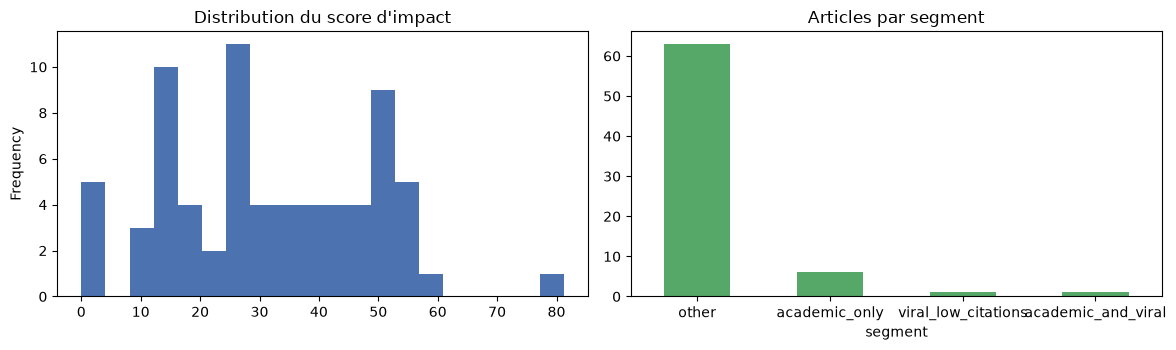

In [11]:
pdf = gold.select("impact_score", "segment", "score_citations", "score_hn", "score_recency").toPandas()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
pdf["impact_score"].plot.hist(bins=20, ax=axes[0], color="#4C72B0", title="Distribution du score d'impact")
pdf["segment"].value_counts().plot.bar(ax=axes[1], rot=0, color="#55A868", title="Articles par segment")
plt.tight_layout()
pdf[["score_citations", "score_hn", "score_recency", "impact_score"]].describe().round(3)

## 7. Les trois questions du dashboard augmenté

In [12]:
print("① Très cités mais absents de Hacker News (academic_only)")
gold.filter("segment = 'academic_only'").select("arxiv_id", "title", "cited_by_count", "citation_percentile").show(truncate=50)
print("② Viraux sur HN mais peu cités (viral_low_citations)")
gold.filter("segment = 'viral_low_citations'").select("arxiv_id", "title", "hn_score_total", "cited_by_count").show(truncate=50)
print("③ Sous-domaines en croissance (croissance annuelle > 0)")
(gold.select("primary_category", "year_published", "category_publications_year", "category_yoy_growth").distinct()
     .filter(F.col("category_yoy_growth") > 0).orderBy(F.desc("year_published"), F.desc("category_yoy_growth")).show(10))

① Très cités mais absents de Hacker News (academic_only)


+----------+--------------------------------------------------+--------------+-------------------+
|  arxiv_id|                                             title|cited_by_count|citation_percentile|
+----------+--------------------------------------------------+--------------+-------------------+
|1706.03762|                         Attention Is All You Need|        120000|                1.0|
|1710.20004|Translation semantic token translation language...|            34|             0.9167|
|2210.20029|Gradient policy policy learning training genera...|            39|                1.0|
|2303.20050|Optimization learning gradient training gradien...|            33|             0.9444|
|2112.20058|Detection detection video recognition visual de...|            40|                1.0|
|2106.20055|Image recognition segmentation depth visual det...|            32|             0.9091|
+----------+--------------------------------------------------+--------------+-------------------+

② Viraux 

+----------+----------------------+--------------+--------------+
|  arxiv_id|                 title|hn_score_total|cited_by_count|
+----------+----------------------+--------------+--------------+
|2303.08774|GPT-4 Technical Report|           912|             2|
+----------+----------------------+--------------+--------------+

③ Sous-domaines en croissance (croissance annuelle > 0)


+----------------+--------------+--------------------------+-------------------+
|primary_category|year_published|category_publications_year|category_yoy_growth|
+----------------+--------------+--------------------------+-------------------+
|           cs.LG|          2023|                        19|             2.1667|
+----------------+--------------+--------------------------+-------------------+



## 8. Écriture dans Elasticsearch (elasticsearch-hadoop)

En production (`SOURCE = "minio"`), `write_elasticsearch` crée l'index `arxiv-papers-enriched` avec son mapping
explicite (`src/utils/mappings.py`), puis écrit via le connecteur `org.elasticsearch.spark.sql` :
`es.mapping.id = arxiv_id` (ré-exécution idempotente), `es.nodes.wan.only = true` (réseau Docker),
`es.index.auto.create = false` (jamais de mapping dynamique). En mode `fixtures`, on vérifie seulement le contrat
de colonnes avec le mapping.

In [13]:
from src.utils.mappings import ENRICHED_PROPERTIES

missing_in_mapping = sorted(set(gold.columns) - set(ENRICHED_PROPERTIES))
print("Colonnes Gold :", len(gold.columns), "| absentes du mapping :", missing_in_mapping or "aucune")
if SOURCE == "minio":
    job.write_elasticsearch(gold, recreate=False)
    print("Documents écrits dans", config.INDEX_ENRICHED)

Colonnes Gold : 46 | absentes du mapping : aucune


In [14]:
spark.stop()